In [ ]:
import tidy3d as td
import numpy as np
import matplotlib.pyplot as plt

print("Tidy3D version:", td.__version__)

Tidy3D version: 2.12.0


In [ ]:
# Operating wavelength
wavelength = 1.55  # micrometers

# Silicon waveguide dimensions
wg_width = 0.50    # micrometers
wg_height = 0.22   # micrometers

# Approximate refractive indices at 1550 nm
n_si = 3.47
n_sio2 = 1.44

# Convert wavelength to frequency for Tidy3D
freq0 = td.C_0 / wavelength

In [ ]:
# Define optical materials
silicon = td.Medium(permittivity=n_si**2)
silica = td.Medium(permittivity=n_sio2**2)

In [ ]:
# Create the 500 nm × 220 nm silicon strip waveguide geometry
waveguide = td.Structure(
    geometry=td.Box(
        center=(0, 0, 0),
        size=(td.inf, wg_width, wg_height),
    ),
    medium=silicon,
)

In [ ]:
# Define the SiO2 simulation region, numerical grid, and absorbing boundaries
sim = td.Simulation(
    size=(10, 2.5, 1.5),
    grid_spec=td.GridSpec.auto(
        min_steps_per_wvl=20,
        wavelength=wavelength,
    ),
    structures=[waveguide],
    medium=silica,
    run_time=1e-12,
    boundary_spec=td.BoundarySpec.all_sides(
        boundary=td.PML()
    ),
)

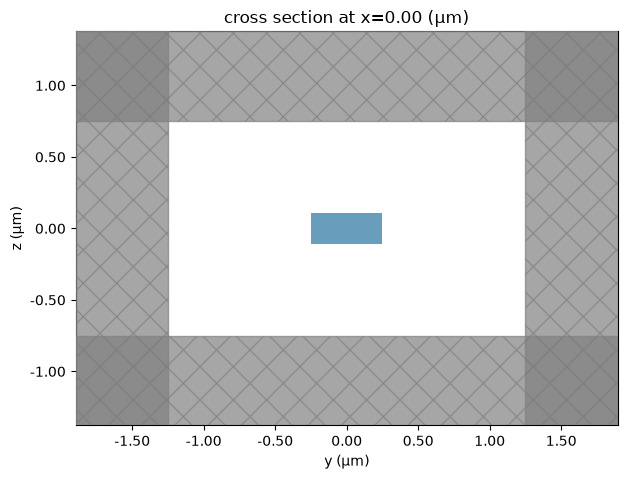

In [ ]:
# Plot the waveguide cross-section to verify the geometry
sim.plot(x=0)
plt.show()

In [ ]:
# Define the y-z cross-section where the optical modes will be solved

mode_plane = td.Box(
    center=(0, 0, 0),
    size=(0, 2.5, 1.5),
)

In [ ]:
# Configure the mode solver to find the first four optical modes

mode_spec = td.ModeSpec(
    num_modes=4,
    target_neff=n_si,
)

In [ ]:
# Create the mode solver using our waveguide, cross-section, and mode settings, only at the specified frequency

from tidy3d.plugins.mode import ModeSolver

mode_solver = ModeSolver(
    simulation=sim,
    plane=mode_plane,
    mode_spec=mode_spec,
    freqs=[freq0],
)

In [ ]:
# Solve for the optical modes supported by the waveguide at 1550 nm

mode_data = mode_solver.solve()

18:05:44 Central Daylight Time WARNING: Use the remote mode solver with subpixel
                               averaging for better accuracy through            
                               'tidy3d.web.run(...)' or the deprecated          
                               'tidy3d.plugins.mode.web.run(...)'.              
                               Alternatively, you can install the package       
                               'tidy3d-extras' using 'pip install "tidy3d"' and 
                               set 'config.simulation.use_local_subpixel=True'. 

18:05:46 Central Daylight Time WARNING: Mode field at frequency index 0, mode   
                               index 2 does not decay at the plane boundaries.  

                               WARNING: Mode field at frequency index 0, mode   
                               index 3 does not decay at the plane boundaries.  

In [ ]:
# Display the calculated effective index and properties of each optical mode

mode_data.to_dataframe()


wavelength     n eff  k eff  loss (dB/cm)  \
f            mode_index                                              
1.934145e+14 0                 1.55  2.413203    0.0           0.0   
             1                 1.55  1.757529    0.0           0.0   
             2                 1.55  1.481491    0.0           0.0   
             3                 1.55  1.337354    0.0           0.0   

                         TE (Ey) fraction  wg TE fraction  wg TM fraction  \
f            mode_index                                                     
1.934145e+14 0                   0.977670        0.744848        0.816525   
             1                   0.046629        0.700782        0.883828   
             2                   0.597820        0.883808        0.964270   
             3                   0.037871        0.986918        0.754276   

                         mode area  
f            mode_index             
1.934145e+14 0            0.198086  
             1            0.364940  
             2            0.855853  
             3            2.493399

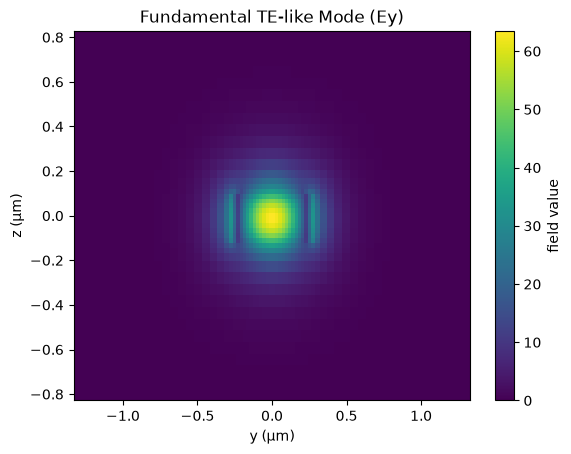

In [ ]:
# Plot the Ey electric-field distribution of the fundamental TE-like mode

mode_data.Ey.isel(f=0, mode_index=0).real.plot(x="y", y="z")
plt.title("Fundamental TE-like Mode (Ey)")
plt.xlabel("y (µm)")
plt.ylabel("z (µm)")
plt.show()

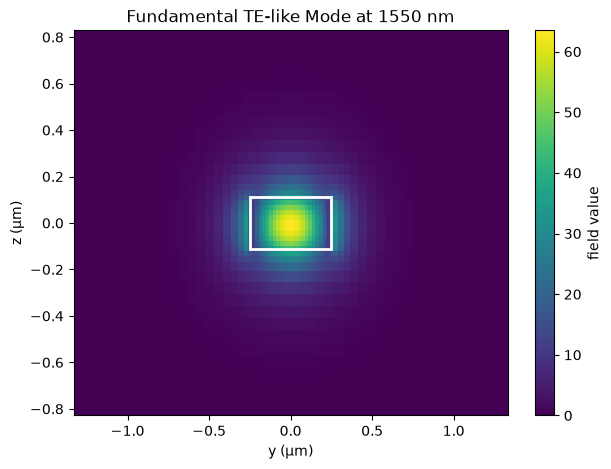

In [ ]:
# Plot the TE0 electric-field profile with the silicon waveguide boundary overlaid

from matplotlib.patches import Rectangle

ey = mode_data.Ey.isel(f=0, mode_index=0).real

fig, ax = plt.subplots(figsize=(7, 5))

ey.plot(x="y", y="z", ax=ax)

waveguide_outline = Rectangle(
    (-wg_width / 2, -wg_height / 2),
    wg_width,
    wg_height,
    fill=False,
    edgecolor="white",
    linewidth=2,
)

ax.add_patch(waveguide_outline)

ax.set_title("Fundamental TE-like Mode at 1550 nm")
ax.set_xlabel("y (µm)")
ax.set_ylabel("z (µm)")

plt.savefig(
    "../Figures/TE0_mode_500nm_waveguide.png",
    dpi=300,
    bbox_inches="tight",
)

plt.show()